In [26]:
import cv2
import librosa
import numpy as np
import matplotlib.pyplot as plt

### **Mel-Spectrogram Extraction**

In [203]:
def get_spectrogram(y, sr):
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)

    # normalize per sample
    mel_db = (mel_db - np.min(mel_db)) / (np.max(mel_db) - np.min(mel_db) + 1e-6)

    # Resize to fixed size
    mel_db = cv2.resize(mel_db, (128, 128))

    return mel_db

### See Mel-Spectrogram

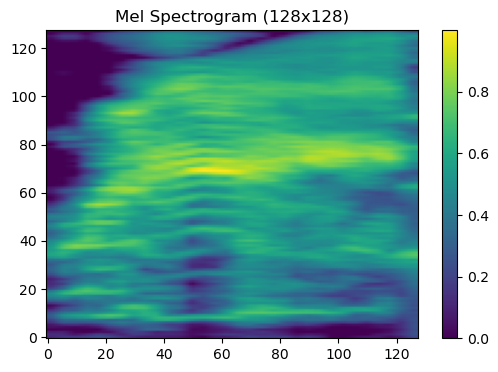

In [144]:
file_path = "dataset/normal/1 newborn crying_expiration.wav"

y, sr = librosa.load(file_path, sr=16000)

# Generate spectrogram
mel_db = get_spectrogram(y, sr)

# Plot
plt.figure(figsize=(6,4))
plt.imshow(mel_db, aspect='auto', origin='lower')
plt.colorbar()
plt.title("Mel Spectrogram (128x128)")
plt.show()

### **Feature Vectors Extraction**

In [204]:
def extract_features(y, sr):
    features = []

    # MFCC
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=16)
    features.extend(np.mean(mfcc, axis=1))
    features.extend(np.std(mfcc, axis=1))

    # Spectral Centroid
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    features.append(np.mean(centroid))
    features.append(np.std(centroid))

    # RMS
    rms = librosa.feature.rms(y=y)
    features.append(np.mean(rms))
    features.append(np.std(rms))

    # ZCR
    zcr = librosa.feature.zero_crossing_rate(y)
    features.append(np.mean(zcr))
    features.append(np.std(zcr))

    # Pitch
    f0 = librosa.yin(y, fmin=50, fmax=1000)
    f0 = f0[~np.isnan(f0)]
    
    if len(f0) > 0:
        features.append(np.mean(f0))
        features.append(np.std(f0))
    else:
        features.append(0)
        features.append(0)

    return np.array(features)

### **Dataset Loader**

In [256]:
import os

X_spec = []
X_feat = []
y = []

def process_folder(folder_path, label):
    for file in os.listdir(folder_path):
        file_path = os.path.join(folder_path, file)

        try:
            y_audio, sr = librosa.load(file_path, sr=16000)

            # Spectrogram
            spec = get_spectrogram(y_audio, sr)

            # Features
            feat = extract_features(y_audio, sr)

            X_spec.append(spec)
            X_feat.append(feat)
            y.append(label)

        except Exception as e:
            print(f"Error processing {file_path}: {e}")

process_folder("dataset/normal", 0)
process_folder("dataset/sepsis", 1)

### **Convert to NumPy Arrays**

In [257]:
X_spec = np.array(X_spec)
X_feat = np.array(X_feat)
y = np.array(y)

# Add channel dimension for CNN
X_spec = X_spec[..., np.newaxis]

print(X_spec.shape)
print(X_feat.shape)
print(y.shape)

(1817, 128, 128, 1)
(1817, 40)
(1817,)


### **Train-Test Split**

In [272]:
from sklearn.model_selection import train_test_split

X_spec_train, X_spec_test, X_feat_train, X_feat_test, y_train, y_test = train_test_split(
    X_spec, X_feat, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_spec_train.shape)
print(X_feat_train.shape)
print(y_train.shape)
print(X_spec_test.shape)
print(X_feat_test.shape)
print(y_test.shape)

(1453, 128, 128, 1)
(1453, 40)
(1453,)
(364, 128, 128, 1)
(364, 40)
(364,)


### **Normalization / Standardization**

In [273]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_feat_train = scaler.fit_transform(X_feat_train)  # fit + transform on train 
X_feat_test = scaler.transform(X_feat_test)         # transform only on test 

X_spec_train = (X_spec_train - np.mean(X_spec_train)) / np.std(X_spec_train)
X_spec_test  = (X_spec_test - np.mean(X_spec_train)) / np.std(X_spec_train)

# X_spec_train = (X_spec_train - np.min(X_spec_train)) / (np.max(X_spec_train) - np.min(X_spec_train))
# X_spec_test  = (X_spec_test - np.min(X_spec_train)) / (np.max(X_spec_train) - np.min(X_spec_train))

### **CNN Only**

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from tensorflow.keras.models import Model

# CNN input
input_img = Input(shape=(128,128,1))

x = Conv2D(32, (3,3), activation='relu')(input_img)
x = MaxPooling2D(2,2)(x)
x = Dropout(0.1)(x)

x = Conv2D(64, (3,3), activation='relu')(x)
x = MaxPooling2D(2,2)(x)
x = Dropout(0.2)(x)

x = Conv2D(128, (3,3), activation='relu')(x)
x = MaxPooling2D(2,2)(x)
x = Dropout(0.3)(x)

x = Flatten()(x)
x = Dropout(0.3)(x)

z = Dense(128, activation='relu')(x)
z = Dropout(0.3)(z)
z = Dense(64, activation='relu')(z)
z = Dropout(0.1)(z)
z = Dense(1, activation='sigmoid')(z)

model = Model(inputs=input_img, outputs=z)

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

Model: "functional_51"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_43 (InputLayer)     │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_69 (Conv2D)              │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_69 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_125 (Dropout)           │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_70 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_70 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_126 (Dropout)           │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_71 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_71 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_127 (Dropout)           │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_21 (Flatten)            │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_128 (Dropout)           │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_85 (Dense)                │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_129 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_130 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_87 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,312,385 (12.64 MB)

 Trainable params: 3,312,385 (12.64 MB)

 Non-trainable params: 0 (0.00 B)

In [192]:
# Training 
model.fit(
    X_spec_train,
    y_train,
    validation_data=(X_spec_test, y_test),
    epochs=20,
    batch_size=32
)

Epoch 1/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 81ms/step - accuracy: 0.7736 - loss: 0.4753 - val_accuracy: 0.7555 - val_loss: 0.6362
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9119 - loss: 0.2153 - val_accuracy: 0.6511 - val_loss: 0.6575
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9429 - loss: 0.1362 - val_accuracy: 0.8709 - val_loss: 0.5678
Epoch 4/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9608 - loss: 0.0995 - val_accuracy: 0.5989 - val_loss: 0.6390
Epoch 5/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9725 - loss: 0.0699 - val_accuracy: 0.5962 - val_loss: 0.6223
Epoch 6/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9835 - loss: 0.0430 - val_accuracy: 0.5797 - val_loss: 0.6672
Epoch 7/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9883 - loss: 0.0312 - val_accuracy: 0.5879 - val_loss: 0.6700
Epoch 8/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9883 - loss: 0.0319 - val_accuracy: 0.7060 - v

In [ ]:
# Evaluation 
loss, acc = model.evaluate(X_spec_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", acc)

# Predictions 
threshold = 0.4
y_pred_prob = model.predict(X_spec_test)
y_pred = (y_pred_prob > threshold).astype(int).reshape(-1)

# Metrics
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

cr = classification_report(y_test, y_pred)
print("\nClassification Report:\n", cr)

auc = roc_auc_score(y_test, y_pred_prob.ravel())
print("ROC-AUC:\n", auc)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7390 - loss: 0.4859
Test Loss: 0.48590025305747986
Test Accuracy: 0.7390109896659851
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Confusion Matrix:
 [[191   2]
 [ 59 112]]

Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.99      0.86       193
           1       0.98      0.65      0.79       171

    accuracy                           0.83       364
   macro avg       0.87      0.82      0.82       364
weighted avg       0.87      0.83      0.83       364

ROC-AUC:
 0.9682150107565979


### **Features Only**

In [116]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization

model = Sequential()

model.add(Input(shape=(X_feat.shape[1],)))

model.add(Dense(128))
model.add(BatchNormalization())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_72 (Dense)                │ (None, 128)            │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_73 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_105 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_74 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_106 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_75 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,593 (119.50 KB)

 Trainable params: 30,337 (118.50 KB)

 Non-trainable params: 256 (1.00 KB)

In [122]:
# Training 
model.fit(
    X_feat_train,
    y_train,
    validation_data=(X_feat_test, y_test),
    epochs=30,
    batch_size=32
)

Epoch 1/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9972 - loss: 0.0083 - val_accuracy: 0.9973 - val_loss: 0.0083
Epoch 2/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9972 - loss: 0.0081 - val_accuracy: 0.9945 - val_loss: 0.0136
Epoch 3/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9945 - loss: 0.0115 - val_accuracy: 0.9918 - val_loss: 0.0174
Epoch 4/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9986 - loss: 0.0033 - val_accuracy: 0.9945 - val_loss: 0.0128
Epoch 5/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9993 - loss: 0.0024 - val_accuracy: 0.9945 - val_loss: 0.0141
Epoch 6/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9972 - loss: 0.0054 - val_accuracy: 0.9945 - val_loss: 0.0130
Epoch 7/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9966 - loss: 0.0107 - val_accuracy: 0.9973 - val_loss: 0.0069
Epoch 8/30
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9972 - loss: 0.0073 - val_accuracy: 0.9945 - val_loss:

In [123]:
# Evaluation 
loss, acc = model.evaluate(X_feat_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", acc)

# Predictions 
y_pred_prob = model.predict(X_feat_test)
y_pred = (y_pred_prob > 0.5).astype(int).reshape(-1)

# print(y_pred_prob[:20])
# print(y_pred[:20])


# Metrics 
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

cr = classification_report(y_test, y_pred)
print("\nClassification Report:\n", cr)

auc = roc_auc_score(y_test, y_pred_prob.ravel())
print("ROC-AUC:\n", auc)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9945 - loss: 0.0135     
Test Loss: 0.01353548001497984
Test Accuracy: 0.9945054650306702
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Confusion Matrix:
 [[193   0]
 [  2 169]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99       193
           1       1.00      0.99      0.99       171

    accuracy                           0.99       364
   macro avg       0.99      0.99      0.99       364
weighted avg       0.99      0.99      0.99       364

ROC-AUC:
 1.0


# **CNN + Feature Fusion Model**

In [274]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D
from tensorflow.keras.layers import Input, Flatten, Dense, Concatenate, Dropout, BatchNormalization, Activation
from tensorflow.keras.models import Model

# CNN input 
input_img = Input(shape=(128,128,1))

x = Conv2D(32, (3,3), activation='relu')(input_img)
x = MaxPooling2D(2,2)(x)
x = Dropout(0.1)(x)

x = Conv2D(64, (3,3), activation='relu')(x)
x = MaxPooling2D(2,2)(x)
x = Dropout(0.2)(x)

x = Conv2D(128, (3,3), activation='relu')(x)
x = MaxPooling2D(2,2)(x)
x = Dropout(0.3)(x)

x = GlobalAveragePooling2D()(x)
# x = Flatten()(x)
# x = Dropout(0.3)(x)

# Feature input 
input_feat = Input(shape=(X_feat.shape[1],))

# Combine
combined = Concatenate()([x, input_feat])

z = Dense(128, activation='relu')(combined)
z = Dropout(0.3)(z)
z = Dense(64, activation='relu')(z)
z = Dropout(0.1)(z)
z = Dense(1, activation='sigmoid')(z)

model = Model(inputs=[input_img, input_feat], outputs=z)

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

Model: "functional_63"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_66      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_105 (Conv2D) │ (None, 126, 126,  │        320 │ input_layer_66[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_105   │ (None, 63, 63,    │          0 │ conv2d_105[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_222         │ (None, 63, 63,    │          0 │ max_pooling2d_10… │
│ (Dropout)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_106 (Conv2D) │ (None, 61, 61,    │     18,496 │ dropout_222[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_106   │ (None, 30, 30,    │          0 │ conv2d_106[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_223         │ (None, 30, 30,    │          0 │ max_pooling2d_10… │
│ (Dropout)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_107 (Conv2D) │ (None, 28, 28,    │     73,856 │ dropout_223[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_107   │ (None, 14, 14,    │          0 │ conv2d_107[0][0]  │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_224         │ (None, 14, 14,    │          0 │ max_pooling2d_10… │
│ (Dropout)           │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ dropout_224[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_67      │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_27      │ (None, 168)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ input_layer_67[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_149 (Dense)   │ (None, 128)       │     21,632 │ concatenate_27[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_225         │ (None, 128)       │          0 │ dense_149[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_150 (Dense)   │ (None, 64)        │      8,256 │ dropout_225[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_226         │ (None, 64)        │          0 │ dense_150[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 122,625 (479.00 KB)

 Trainable params: 122,625 (479.00 KB)

 Non-trainable params: 0 (0.00 B)

### **Training**

In [275]:
model.fit(
    [X_spec_train, X_feat_train],
    y_train,
    validation_data=([X_spec_test, X_feat_test], y_test),
    epochs=20,
    batch_size=32
)

Epoch 1/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 104ms/step - accuracy: 0.7997 - loss: 0.4240 - val_accuracy: 0.9231 - val_loss: 0.2899
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.9229 - loss: 0.2025 - val_accuracy: 0.9368 - val_loss: 0.2077
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.9525 - loss: 0.1319 - val_accuracy: 0.9505 - val_loss: 0.1586
Epoch 4/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.9670 - loss: 0.1058 - val_accuracy: 0.9588 - val_loss: 0.1296
Epoch 5/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.9704 - loss: 0.0839 - val_accuracy: 0.9643 - val_loss: 0.1099
Epoch 6/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.9842 - loss: 0.0568 - val_accuracy: 0.9560 - val_loss: 0.1142
Epoch 7/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.9849 - loss: 0.0477 - val_accuracy: 0.9698 - val_loss: 0.0960
Epoch 8/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.9849 - loss: 0.0429 - val_accuracy: 0.

### **Evaluation**

In [276]:
# Evaluation 
loss, acc = model.evaluate([X_spec_test, X_feat_test], y_test)
print("Test Loss:", loss)
print("Test Accuracy:", acc)

# Predictions 
threshold = 0.4
y_pred_prob = model.predict([X_spec_test, X_feat_test])
y_pred = (y_pred_prob > threshold).astype(int).reshape(-1)

# Metrics
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

cr = classification_report(y_test, y_pred)
print("\nClassification Report:\n", cr)

auc = roc_auc_score(y_test, y_pred_prob.ravel())
print("ROC-AUC:\n", auc)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9780 - loss: 0.0665
Test Loss: 0.06653787940740585
Test Accuracy: 0.9780219793319702
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Confusion Matrix:
 [[192   1]
 [  5 166]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98       193
           1       0.99      0.97      0.98       171

    accuracy                           0.98       364
   macro avg       0.98      0.98      0.98       364
weighted avg       0.98      0.98      0.98       364

ROC-AUC:
 0.9977880798715268


# **Crynet**

In [269]:
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, BatchNormalization
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D
from tensorflow.keras.layers import Activation, Concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# =========================
# 🔹 CNN BRANCH
# =========================
input_img = Input(shape=(128,128,1))

x = Conv2D(32, (3,3), activation='relu', padding='same')(input_img)
x = MaxPooling2D(2,2)(x)
x = Dropout(0.1)(x)

x = Conv2D(64, (3,3), activation='relu', padding='same')(x)
x = MaxPooling2D(2,2)(x)
x = Dropout(0.2)(x)

x = Conv2D(128, (3,3), activation='relu', padding='same')(x)
x = MaxPooling2D(2,2)(x)
x = Dropout(0.3)(x)

x = GlobalAveragePooling2D()(x)
# x = Flatten()(x)
# x = Dropout(0.3)(x)

# # 🔥 CNN embedding
# x = Dense(256, activation='relu')(x)
# x = Dropout(0.3)(x)

x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)

# =========================
# 🔹 FEATURE BRANCH
# =========================
input_feat = Input(shape=(X_feat.shape[1],))

f = Dense(128, activation='relu')(input_feat)
f = Dropout(0.3)(f)

f = Dense(64, activation='relu')(f)
f = Dropout(0.2)(f)

# =========================
# 🔥 FUSION
# =========================
combined = Concatenate()([x, f])

z = Dense(128, activation='relu')(combined)
z = Dropout(0.3)(z)

z = Dense(64, activation='relu')(z)
z = Dropout(0.2)(z)

output = Dense(1, activation='sigmoid')(z)

# =========================
# MODEL
# =========================
model = Model(inputs=[input_img, input_feat], outputs=output)

# compile
model.compile(
    optimizer=Adam(learning_rate=0.0003),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_62"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_64      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_102 (Conv2D) │ (None, 128, 128,  │        320 │ input_layer_64[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_102   │ (None, 64, 64,    │          0 │ conv2d_102[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_214         │ (None, 64, 64,    │          0 │ max_pooling2d_10… │
│ (Dropout)           │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_103 (Conv2D) │ (None, 64, 64,    │     18,496 │ dropout_214[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_103   │ (None, 32, 32,    │          0 │ conv2d_103[0][0]  │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_215         │ (None, 32, 32,    │          0 │ max_pooling2d_10… │
│ (Dropout)           │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_104 (Conv2D) │ (None, 32, 32,    │     73,856 │ dropout_215[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_104   │ (None, 16, 16,    │          0 │ conv2d_104[0][0]  │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_65      │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_216         │ (None, 16, 16,    │          0 │ max_pooling2d_10… │
│ (Dropout)           │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_144 (Dense)   │ (None, 128)       │      5,248 │ input_layer_65[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ dropout_216[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_218         │ (None, 128)       │          0 │ dense_144[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_143 (Dense)   │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_145 (Dense)   │ (None, 64)        │      8,256 │ dropout_218[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_217         │ (None, 128)       │          0 │ dense_143[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_219         │ (None, 64)        │          0 │ dense_145[0][0] 

 Total params: 155,713 (608.25 KB)

 Trainable params: 155,713 (608.25 KB)

 Non-trainable params: 0 (0.00 B)

### **Training**

In [270]:
model.fit(
    [X_spec_train, X_feat_train],
    y_train,
    validation_data=([X_spec_test, X_feat_test], y_test),
    epochs=10,
    batch_size=32
)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 119ms/step - accuracy: 0.6538 - loss: 0.6382 - val_accuracy: 0.8049 - val_loss: 0.5675
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 116ms/step - accuracy: 0.8107 - loss: 0.4528 - val_accuracy: 0.8626 - val_loss: 0.3792
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.8761 - loss: 0.3124 - val_accuracy: 0.9011 - val_loss: 0.2751
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 116ms/step - accuracy: 0.9002 - loss: 0.2490 - val_accuracy: 0.9121 - val_loss: 0.2360
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 116ms/step - accuracy: 0.9319 - loss: 0.1935 - val_accuracy: 0.9286 - val_loss: 0.2014
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.9367 - loss: 0.1544 - val_accuracy: 0.9258 - val_loss: 0.1878
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 117ms/step - accuracy: 0.9525 - loss: 0.1396 - val_accuracy: 0.9368 - val_loss: 0.1575
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 118ms/step - accuracy: 0.9594 - loss: 0.1279 - val_accuracy: 0.

### **Evaluation**

In [271]:
# Evaluation 
loss, acc = model.evaluate([X_spec_test, X_feat_test], y_test)
print("Test Loss:", loss)
print("Test Accuracy:", acc)

# Predictions 
threshold = 0.4
y_pred_prob = model.predict([X_spec_test, X_feat_test])
y_pred = (y_pred_prob > threshold).astype(int).reshape(-1)

# Metrics 
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

cr = classification_report(y_test, y_pred)
print("\nClassification Report:\n", cr)

auc = roc_auc_score(y_test, y_pred_prob.ravel())
print("ROC-AUC:\n", auc)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9478 - loss: 0.1314
Test Loss: 0.13137194514274597
Test Accuracy: 0.9478021860122681
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Confusion Matrix:
 [[186   7]
 [  9 162]]

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.96      0.96       193
           1       0.96      0.95      0.95       171

    accuracy                           0.96       364
   macro avg       0.96      0.96      0.96       364
weighted avg       0.96      0.96      0.96       364

ROC-AUC:
 0.9927582340999304
